# Flat-bottom instability: Rayleigh equation vs Ohshima theory (`h=1`)

This notebook checks two independent routes to the same flat-bottom (no
topography) shear-instability problem against each other, then explores how
the results look for a few different jet speeds `U0`.

Both routes use the same jet profile established in the derivation notebook:

$$U(y) = \frac{U_0}{2}\tanh\!\left(\frac{y-Y_j}{L_{jet}}\right)
\qquad\Longleftrightarrow\qquad
\hat v(\hat x) = \tfrac12\tanh(\hat x)$$

**Contents**

| Section | What it does |
|---|---|
| 1 | The classic Rayleigh equation for a flat bottom, solved with the Dickinson & Clare (1973) 4th-order Numerov + Newton method |
| 2 | Ohshima's general (topography-capable) theory, with `h=1` everywhere (flat), solved with this notebook's own generalized-eigenvalue method |
| 3 | Overlay both growth-rate curves to compare |
| 4 | Repeat for `U0 = 0.2, 0.3, 0.4` m/s -- nondimensional check, plus the dimensional growth-rate/wavelength curves this actually produces |


In [1]:
import numpy as np
import matplotlib.pyplot as plt

---
# Section 1 -- Rayleigh equation for a flat bottom (Dickinson & Clare 1973 method)

Solves

$$(U-c)(\psi''-\alpha^2\psi) + (\beta-U'')\psi = 0, \qquad \beta=0$$

for $U(\hat x)=\tfrac12\tanh(\hat x)$

In [2]:
# ---- grid ----
xmin, xmax = -10.0, 10.0
N = 2500
X = np.linspace(xmin, xmax, N)
h = X[1] - X[0]

# ---- profile: v_hat = tanh(x)/2, beta=0 ----
beta = 0.0
U = 0.5 * np.tanh(X)
Uxx = -np.tanh(X) / np.cosh(X)**2   # d/dx[0.5*sech^2(x)] = -tanh(x)*sech^2(x)


def initial_guess(Nc, alpha2, beta):
    """Coarse 2nd-order generalized-eigenvalue solve -> most unstable c."""
    Xc = np.linspace(xmin, xmax, Nc)
    hc = Xc[1] - Xc[0]
    Uc = 0.5 * np.tanh(Xc)
    Uxxc = -np.tanh(Xc) / np.cosh(Xc)**2
    main = -2.0 * np.ones(Nc); off = np.ones(Nc - 1)
    D2 = (np.diag(main) + np.diag(off, 1) + np.diag(off, -1)) / hc**2
    Lap = D2 - alpha2 * np.eye(Nc)
    L = np.diag(Uc) @ Lap + np.diag(beta - Uxxc)
    from scipy.linalg import eig
    w, _ = eig(L, Lap)
    w = w[np.isfinite(w)]
    sel = (w.real > Uc.min() - 0.2) & (w.real < Uc.max() + 0.2)
    if np.any(sel):
        w = w[sel]
    return w[np.argmax(w.imag)]


def Qfunc(c, alpha2):
    return (beta - Uxx) / (c - U) + alpha2


def branch_decay(arg):
    l = np.sqrt(complex(arg))
    return -l if l.imag > 0 else l


def build_A(c, alpha2):
    Q = Qfunc(c, alpha2)
    h2 = h * h
    diag = np.empty(N, dtype=complex); sub = np.zeros(N, dtype=complex); sup = np.zeros(N, dtype=complex)
    diag[1:-1] = -2.0 - (5.0 / 6.0) * Q[1:-1] * h2
    sub[1:-1] = 1.0 - Q[:-2] * h2 / 12.0
    sup[1:-1] = 1.0 - Q[2:] * h2 / 12.0
    l_minus = branch_decay(beta / (-c) - alpha2)
    l_plus = branch_decay(beta / (1.0 - c) - alpha2)
    diag[0] = -1.0 / h - 1j * l_minus / 2.0
    sup[0] = 1.0 / h - 1j * l_minus / 2.0
    sub[-1] = -1.0 / h + 1j * l_plus / 2.0
    diag[-1] = 1.0 / h + 1j * l_plus / 2.0
    return sub, diag, sup


def det_A(c, alpha2):
    sub, diag, sup = build_A(c, alpha2)
    f_prev2 = 1.0 + 0j
    f_prev1 = diag[0]
    for i in range(1, N):
        f = diag[i] * f_prev1 - sub[i] * sup[i - 1] * f_prev2
        m = abs(f)
        if m > 1e150 or (0.0 < m < 1e-150):
            f /= m; f_prev1 /= m
        f_prev2, f_prev1 = f_prev1, f
    return f_prev1


def find_eigenvalue(c0, alpha2, tol=1e-11, maxit=60):
    c = complex(c0)
    for it in range(1, maxit + 1):
        f = det_A(c, alpha2)
        dc = 1e-7 * (1.0 + abs(c))
        fp = (det_A(c + dc, alpha2) - det_A(c - dc, alpha2)) / (2.0 * dc)
        step = f / fp
        c -= step
        if abs(step) < tol * (1.0 + abs(c)):
            break
    return c


def solve_flat_rayleigh(alpha2, c_guess=None, Nc_guess=400):
    c0 = c_guess if c_guess is not None else initial_guess(Nc_guess, alpha2, beta)
    return find_eigenvalue(c0, alpha2)


### 1.1 Growth rate vs wavenumber

In [3]:
alphas_1 = np.linspace(0.05, 1.0, 60)   # restricted to the confirmed-unstable band --
                                          # see the markdown note below for why
omega_i_1 = np.zeros_like(alphas_1)
c_prev = None
for i, a in enumerate(alphas_1):
    c = solve_flat_rayleigh(a**2, c_guess=c_prev)
    omega_i_1[i] = max(a * c.imag, 0.0)   # clip: Newton continuation can drift onto a
                                            # spurious branch right at/past the neutral
                                            # boundary and return a small positive "growth"
                                            # that isn't real -- physically sigma_i>=0 with
                                            # equality outside the unstable band, so any
                                            # negative result is discarded, and see note below
                                            # about why the domain itself is truncated
    c_prev = c   # continuation -- reuse previous root as next guess for smoothness

imax1 = np.argmax(omega_i_1)
print(f"Section 1 (Rayleigh/Dickinson-Clare): peak growth {omega_i_1[imax1]:.4f} "
      f"at alpha={alphas_1[imax1]:.3f}")


Section 1 (Rayleigh/Dickinson-Clare): peak growth 0.0948 at alpha=0.453


### 1.2 Plot -- Section 1 flat-bottom curve

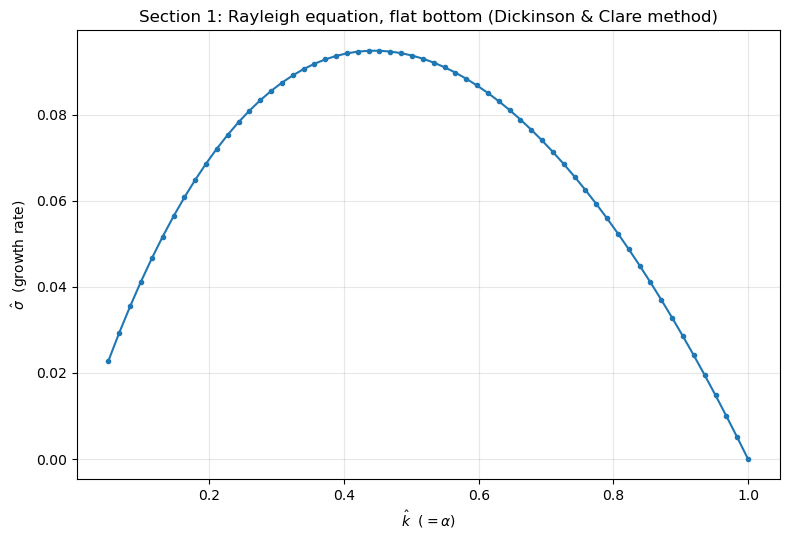

In [4]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(alphas_1, omega_i_1, 'C0-o', markersize=3)
ax.set_xlabel(r"$\hat k$  ($=\alpha$)")
ax.set_ylabel(r"$\hat\sigma$  (growth rate)")
ax.set_title("Section 1: Rayleigh equation, flat bottom (Dickinson & Clare method)")
ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()


---
# Section 2 -- Ohshima theory with `h=1` (flat bottom)



In [5]:
ARCTANH95 = np.arctanh(0.95)

def v_jet_shape(x, Xj_nd, Ljet_nd=1.0):
    x = np.asarray(x, dtype=float)
    return 0.5 * np.tanh((x - Xj_nd) / Ljet_nd)


def h_flat(x, hs_nd, Xs_nd, Ws_nd=1.0):
    return np.full_like(np.asarray(x, dtype=float), hs_nd)


def domain_bounds(Xj_nd, Ljet_nd, Xs_nd, jet_mult=4.0, Ws_nd=1.0):
    x_min = min(Xs_nd - 0.5 * Ws_nd, Xj_nd - jet_mult * Ljet_nd)
    x_max = max(Xs_nd + 0.5 * Ws_nd, Xj_nd + jet_mult * Ljet_nd)
    return x_min, x_max


def build_and_solve_flat(k, Ro, N=400, jet_mult=5.0):
    Xj_nd, Ljet_nd, hs_nd = 0.0, 1.0, 1.0
    x_min, x_max = domain_bounds(Xj_nd, Ljet_nd, 0.0, jet_mult=jet_mult, Ws_nd=1.0)
    xnode = np.linspace(x_min, x_max, N + 1)
    vnode = v_jet_shape(xnode, Xj_nd, Ljet_nd)
    dx = (x_max - x_min) / N
    vp_shape_strip = (vnode[1:] - vnode[:-1]) / dx
    h_strip = np.full(N, hs_nd)

    unknowns = []
    def add_unknown(name):
        unknowns.append(name); return len(unknowns) - 1

    regions = []
    idxA0 = add_unknown("A0")
    regions.append(dict(kind="outerleft", h=hs_nd, vp=0.0, coefs={"A": idxA0}, anchor=x_min))
    idxA1 = add_unknown("A1"); idxB1 = add_unknown("B1")
    regions.append(dict(kind="interior", h=h_strip[0], vp=vp_shape_strip[0],
                         coefs={"A": idxA1, "B": idxB1}, xL=xnode[0]))
    for i in range(2, N + 1):
        idxA = add_unknown(f"A{i}"); idxB = add_unknown(f"B{i}")
        regions.append(dict(kind="interior", h=h_strip[i - 1], vp=vp_shape_strip[i - 1],
                             coefs={"A": idxA, "B": idxB}, xL=xnode[i - 1]))
    idxBout = add_unknown(f"B{N+1}")
    regions.append(dict(kind="outerright", h=hs_nd, vp=0.0, coefs={"B": idxBout}, anchor=x_max))
    Nu = len(unknowns)

    def basis_rows(region, x):
        val = np.zeros(Nu, dtype=complex); der = np.zeros(Nu, dtype=complex)
        kind = region["kind"]; c = region["coefs"]
        if kind == "outerleft":
            iA = c["A"]; a = region["anchor"]
            e = np.exp(k * (x - a)); val[iA] = e; der[iA] = k * e
        elif kind == "outerright":
            iB = c["B"]; a = region["anchor"]
            e = np.exp(-k * (x - a)); val[iB] = e; der[iB] = -k * e
        else:
            iA, iB = c["A"], c["B"]; xL = region["xL"]
            ep = np.exp(k * (x - xL)); em = np.exp(-k * (x - xL))
            val[iA] = ep; val[iB] = em
            der[iA] = k * ep; der[iB] = -k * em
        return val, der

    matches = [(xnode[0], regions[0], regions[1], vnode[0])]
    matches += [(xnode[j], regions[j], regions[j + 1], vnode[j]) for j in range(1, N + 1)]

    from scipy.linalg import eig
    B = np.zeros((Nu, Nu), dtype=complex); D = np.zeros((Nu, Nu), dtype=complex)
    row = 0
    for (x_j, Lreg, Rreg, v_j) in matches:
        valL, derL = basis_rows(Lreg, x_j); valR, derR = basis_rows(Rreg, x_j)
        hL, hR = Lreg["h"], Rreg["h"]
        PL = (1.0 + Ro * Lreg["vp"]) / hL
        PR = (1.0 + Ro * Rreg["vp"]) / hR
        B[row, :] = valR - valL; D[row, :] = 0.0; row += 1
        jump_hinv_der = derR / hR - derL / hL
        jump_Pphi = PR * valR - PL * valL
        D[row, :] = Ro * jump_hinv_der
        B[row, :] = Ro * v_j * k * jump_hinv_der - k * jump_Pphi
        row += 1
    ev = eig(B, D, right=False)
    return ev[np.isfinite(ev)]


def growth_rate_flat(k, Ro=1.0, N=400):
    sig = build_and_solve_flat(k, Ro, N=N)
    sig = sig[np.abs(sig) < 10.0]
    u = sig[sig.imag > 1e-8]
    return u.imag.max() if u.size else 0.0


### 2.1 Growth rate vs wavenumber

In [6]:
ks_2 = np.linspace(0.05, 1.2, 60)
omega_i_2 = np.array([growth_rate_flat(k, Ro=1.0, N=400) for k in ks_2])

imax2 = np.argmax(omega_i_2)
print(f"Section 2 (Ohshima theory, h=1): peak growth {omega_i_2[imax2]:.4f} "
      f"at k={ks_2[imax2]:.3f}")


Section 2 (Ohshima theory, h=1): peak growth 0.0948 at k=0.440


### 2.2 `Ro`-invariance check



In [7]:
Ro_test_vals = [0.5, 1.0, 2.0, 5.0]
k_check = 0.45
vals = [growth_rate_flat(k_check, Ro=r, N=400) for r in Ro_test_vals]
print(f"{'Ro':>6s} {'growth at k=0.45':>18s}")
for r, v in zip(Ro_test_vals, vals):
    print(f"{r:6.2f} {v:18.6f}")
print(f"\nmax deviation from mean: {max(abs(np.array(vals)-np.mean(vals))):.2e}")


    Ro   growth at k=0.45
  0.50           0.094832
  1.00           0.094832
  2.00           0.094832
  5.00           0.094832

max deviation from mean: 1.87e-12


### 2.3 Plot -- Section 2 flat-bottom curve

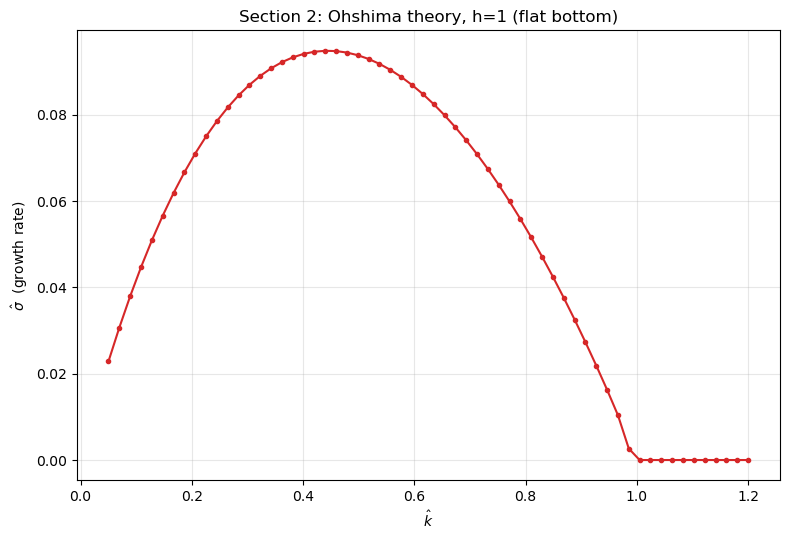

In [8]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(ks_2, omega_i_2, 'C3-o', markersize=3)
ax.set_xlabel(r"$\hat k$")
ax.set_ylabel(r"$\hat\sigma$  (growth rate)")
ax.set_title("Section 2: Ohshima theory, h=1 (flat bottom)")
ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()


---
# Section 3 -- Overlap comparison




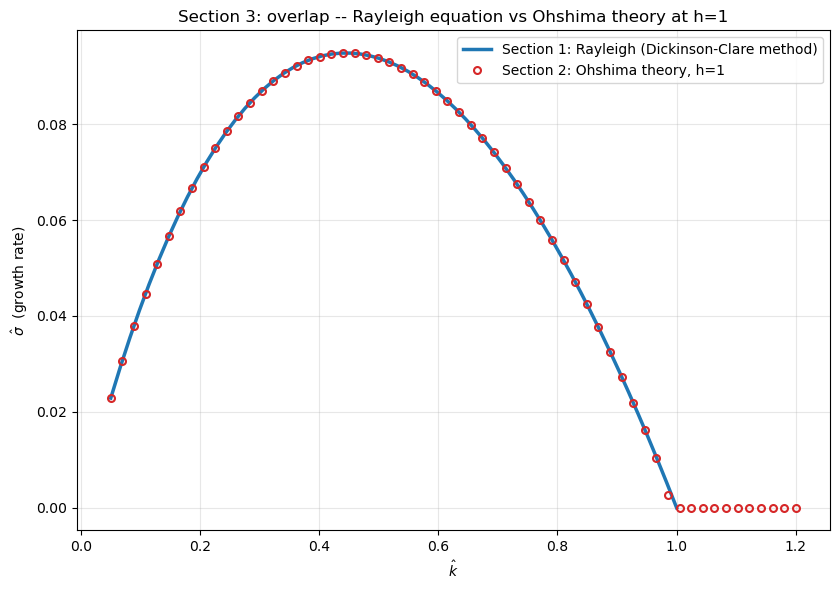

max|Section2 - Section1| (interpolated to common grid): 1.88e-03
peak growth -- Section 1: 0.0948 at alpha=0.453
peak growth -- Section 2: 0.0948 at k=0.440


In [9]:
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.plot(alphas_1, omega_i_1, 'C0-', linewidth=2.5, label="Section 1: Rayleigh (Dickinson-Clare method)")
ax.plot(ks_2, omega_i_2, 'C3o', markersize=5, markerfacecolor='none', markeredgewidth=1.5,
        label="Section 2: Ohshima theory, h=1")
ax.set_xlabel(r"$\hat k$")
ax.set_ylabel(r"$\hat\sigma$  (growth rate)")
ax.set_title("Section 3: overlap -- Rayleigh equation vs Ohshima theory at h=1")
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

# quantitative check on the shared grid
omega_i_1_on_ks2 = np.interp(ks_2, alphas_1, omega_i_1)
diff = np.abs(omega_i_2 - omega_i_1_on_ks2)
print(f"max|Section2 - Section1| (interpolated to common grid): {diff.max():.2e}")
print(f"peak growth -- Section 1: {omega_i_1.max():.4f} at alpha={alphas_1[np.argmax(omega_i_1)]:.3f}")
print(f"peak growth -- Section 2: {omega_i_2.max():.4f} at k={ks_2[np.argmax(omega_i_2)]:.3f}")


---
# Section 4 -- Trying `U0 = 0.2, 0.3, 0.4` m/s



### 4.1 Nondimensional curves for `U0 = 0.2, 0.3, 0.4` 

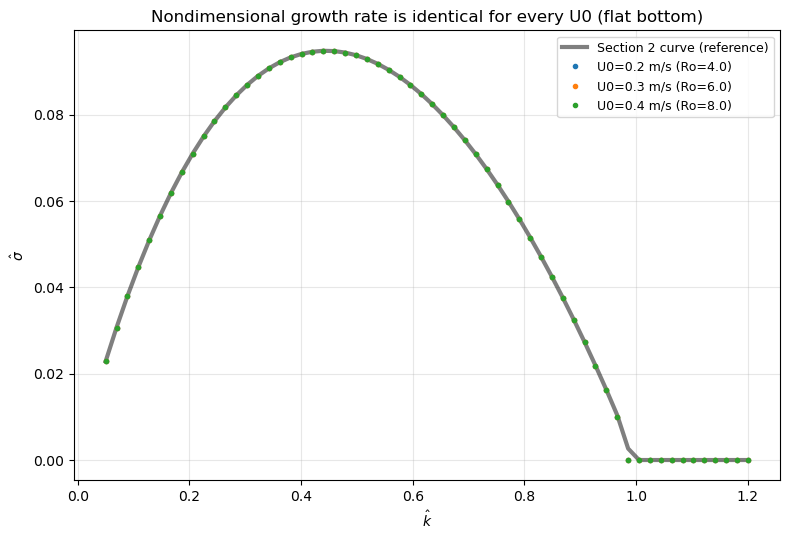

In [10]:
U0_values = [0.2, 0.3, 0.4]   # m/s -- these don't enter the nondimensional solve at all,
                                # included here only to make the point explicit
f_illustrative = 1e-5          # s^-1, illustrative -- also cancels out for h=1

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(ks_2, omega_i_2, 'k-', linewidth=3, alpha=0.5, label="Section 2 curve (reference)")
for U0 in U0_values:
    # Ro = U0/(f*Ljet) varies with U0, but growth_rate_flat is Ro-independent for h=1 --
    # plug in a representative Ljet=5000m just to compute a concrete Ro and show it doesn't matter
    Ro_this = U0 / (f_illustrative * 5000.0)
    gi = np.array([growth_rate_flat(k, Ro=Ro_this, N=300) for k in ks_2])
    ax.plot(ks_2, gi, 'o', markersize=3, label=f"U0={U0} m/s (Ro={Ro_this:.1f})")

ax.set_xlabel(r"$\hat k$")
ax.set_ylabel(r"$\hat\sigma$")
ax.set_title("Nondimensional growth rate is identical for every U0 (flat bottom)")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()


### 4.2 Dimensional growth-rate / wavelength curves for each `U0`



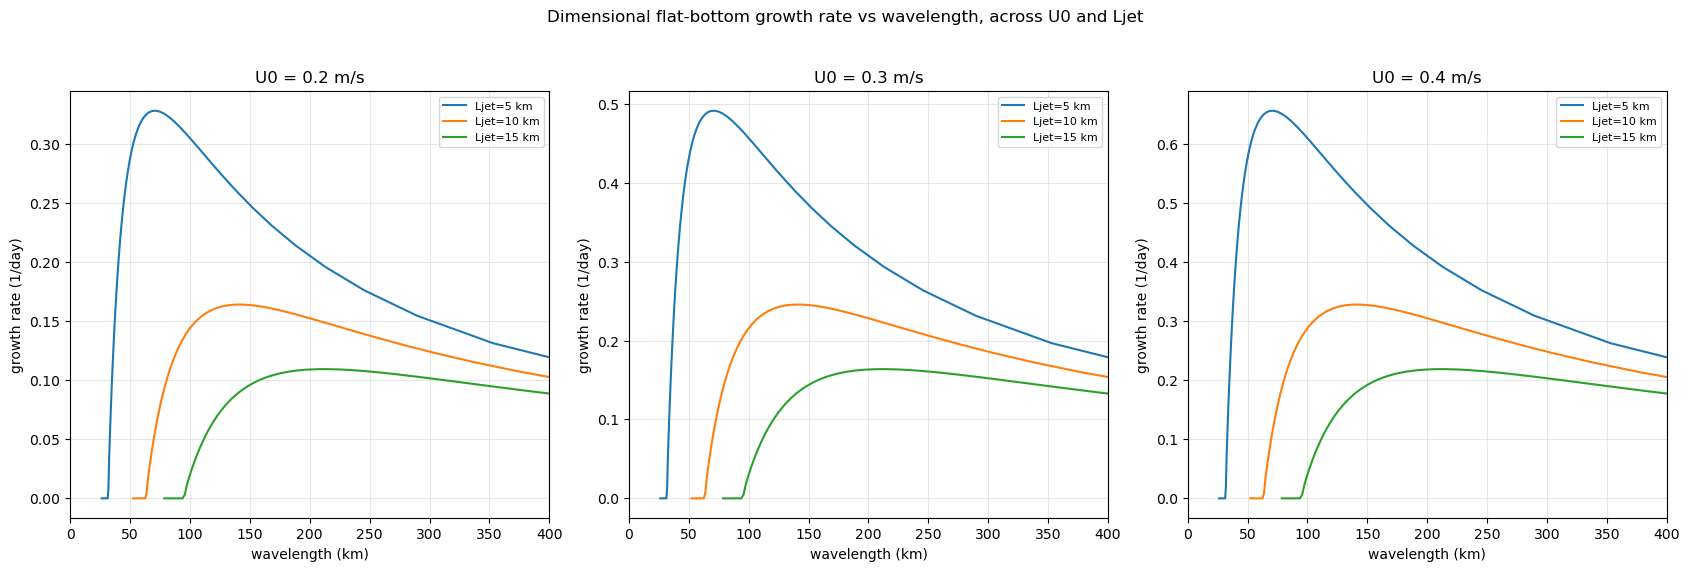

 U0 (m/s)  Ljet (km)  peak growth (1/day)  wavelength at peak (km)
      0.2          5               0.3277                     71.4
      0.2         10               0.1639                    142.9
      0.2         15               0.1092                    214.3
      0.3          5               0.4916                     71.4
      0.3         10               0.2458                    142.9
      0.3         15               0.1639                    214.3
      0.4          5               0.6555                     71.4
      0.4         10               0.3277                    142.9
      0.4         15               0.2185                    214.3


In [11]:
Ljet_values_m = [5000.0, 10000.0, 15000.0]
colors_ljet = {5000.0: 'C0', 10000.0: 'C1', 15000.0: 'C2'}
styles_u0 = {0.2: '-', 0.3: '--', 0.4: ':'}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=False)

for ax, U0 in zip(axes, U0_values):
    for Ljet in Ljet_values_m:
        wavelength_km = (2 * np.pi * Ljet / ks_2) / 1e3
        growth_per_day = omega_i_2 * (U0 / Ljet) * 86400.0
        ax.plot(wavelength_km, growth_per_day, color=colors_ljet[Ljet],
                label=f"Ljet={Ljet/1e3:.0f} km")
    ax.set_xlabel("wavelength (km)")
    ax.set_ylabel("growth rate (1/day)")
    ax.set_title(f"U0 = {U0} m/s")
    ax.set_xlim(0, 400)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.suptitle("Dimensional flat-bottom growth rate vs wavelength, across U0 and Ljet", y=1.03)
fig.tight_layout(); plt.show()

print(f"{'U0 (m/s)':>9s} {'Ljet (km)':>10s} {'peak growth (1/day)':>20s} {'wavelength at peak (km)':>24s}")
for U0 in U0_values:
    for Ljet in Ljet_values_m:
        growth_per_day = omega_i_2 * (U0 / Ljet) * 86400.0
        wavelength_km = (2 * np.pi * Ljet / ks_2) / 1e3
        ipeak = np.argmax(growth_per_day)
        print(f"{U0:9.1f} {Ljet/1e3:10.0f} {growth_per_day[ipeak]:20.4f} {wavelength_km[ipeak]:24.1f}")


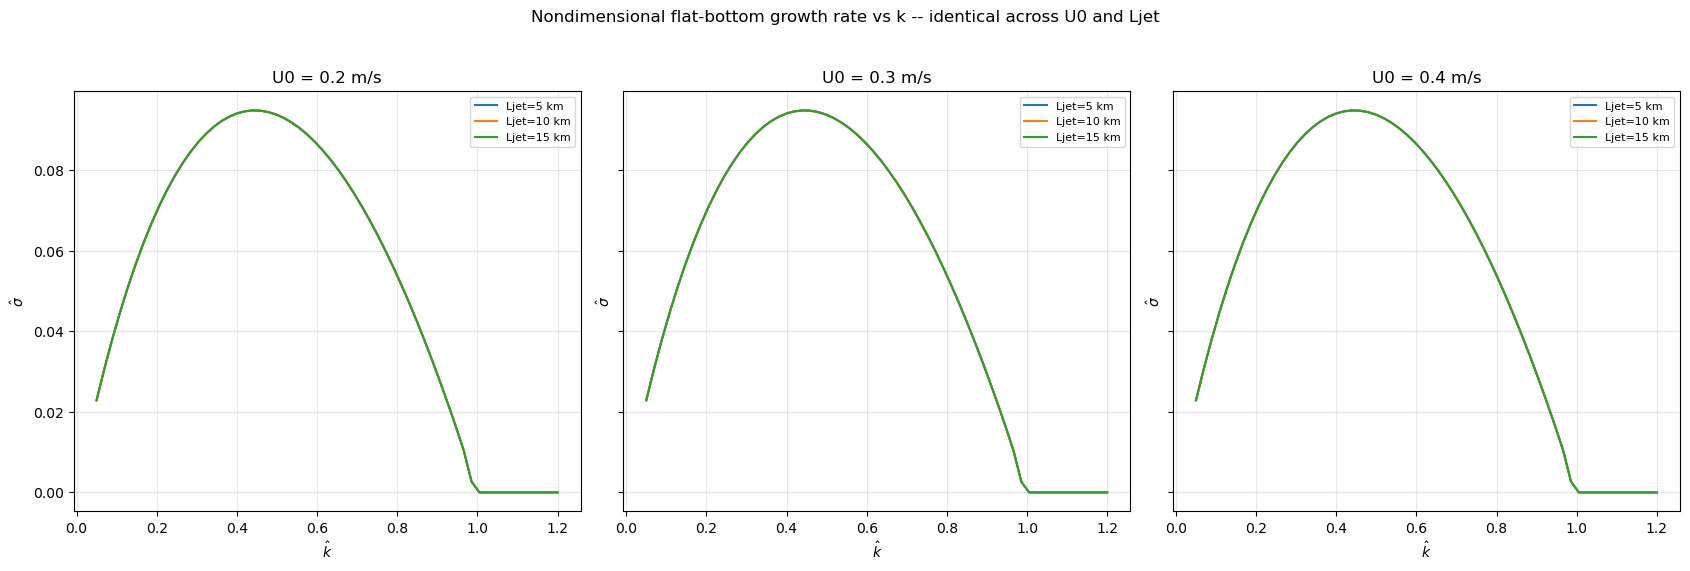

 U0 (m/s)  Ljet (km)   peak sigma_hat  k at peak
      0.2          5           0.0948      0.440
      0.2         10           0.0948      0.440
      0.2         15           0.0948      0.440
      0.3          5           0.0948      0.440
      0.3         10           0.0948      0.440
      0.3         15           0.0948      0.440
      0.4          5           0.0948      0.440
      0.4         10           0.0948      0.440
      0.4         15           0.0948      0.440


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)

for ax, U0 in zip(axes, U0_values):
    for Ljet in Ljet_values_m:
        # nondimensional axes -- k_hat and sigma_hat never depend on U0 or Ljet,
        # so every line in every panel is the exact same curve
        ax.plot(ks_2, omega_i_2, color=colors_ljet[Ljet],
                label=f"Ljet={Ljet/1e3:.0f} km")
    ax.set_xlabel(r"$\hat k$")
    ax.set_ylabel(r"$\hat\sigma$")
    ax.set_title(f"U0 = {U0} m/s")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.suptitle("Nondimensional flat-bottom growth rate vs k -- identical across U0 and Ljet", y=1.03)
fig.tight_layout(); plt.show()

print(f"{'U0 (m/s)':>9s} {'Ljet (km)':>10s} {'peak sigma_hat':>16s} {'k at peak':>10s}")
for U0 in U0_values:
    for Ljet in Ljet_values_m:
        ipeak = np.argmax(omega_i_2)
        print(f"{U0:9.1f} {Ljet/1e3:10.0f} {omega_i_2[ipeak]:16.4f} {ks_2[ipeak]:10.3f}")